# EMA filter, explored

A single EMA (exponential moving average) stage is a first-order IIR low-pass: $y[n] = y[n-1] + \alpha\,(x[n] - y[n-1])$. This is the building block behind the SR860/MFLI demodulator's time-constant filter.

$\alpha$ isn't set directly — you set a time constant $\tau$ instead, and $\alpha = 1 - e^{-T_s/\tau}$ converts it for a given sample period $T_s$. This notebook checks `ema_float.py` against the two closed-form results theory predicts: the step response and the -3dB bandwidth.

In [6]:
import sys
sys.path.insert(0, '../models')

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from ema_float import alpha_from_tau, ema_filter, f3db

## Step response vs. the analytic $1 - e^{-t/\tau}$

Feeding a unit step into a first-order low-pass should climb toward 1 following $1 - e^{-t/\tau}$, same as an RC circuit charging. `Ts` and `tau` below are placeholders — swap in the real ADC rate and a representative time constant once that's settled.

alpha = 0.001


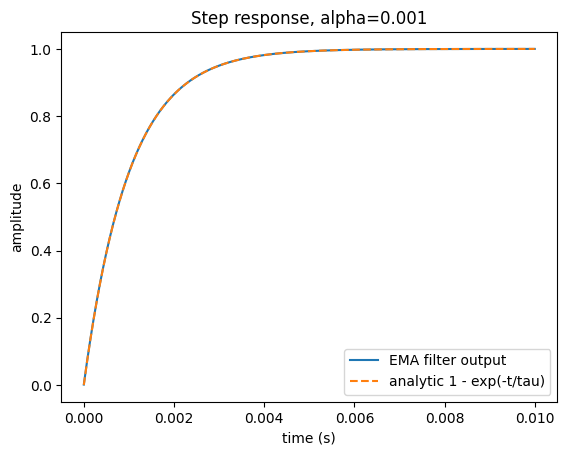

In [7]:
Ts = 1e-6   # placeholder sample period
tau = 1e-3  # placeholder time constant

alpha = alpha_from_tau(tau, Ts)
print(f'alpha = {alpha:.3g}')

n_samples = int(10 * tau / Ts)
t = np.arange(n_samples) * Ts
x = np.ones(n_samples)
y = ema_filter(x, alpha)

plt.plot(t, y, label='EMA filter output')
plt.plot(t, 1 - np.exp(-t / tau), '--', label='analytic 1 - exp(-t/tau)')
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.legend()
plt.title(f'Step response, alpha={alpha:.3g}')
plt.show()

## Frequency response vs. the theoretical -3dB point

For a single stage ($n = 1$), $f_{3\mathrm{dB}} = \frac{\sqrt{2^{1/1} - 1}}{2\pi\tau} = \frac{1}{2\pi\tau}$. Computing the filter's actual frequency response with `scipy.signal.freqz` and checking the magnitude at that frequency should land right on -3dB.

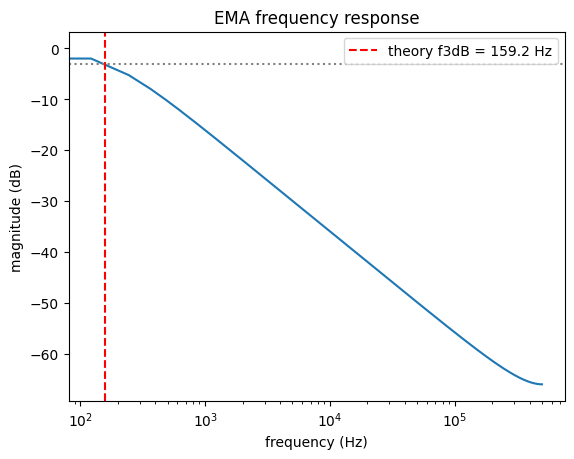

magnitude at theoretical f3dB: -3.010 dB (should be close to -3.0)


In [8]:
# y[n] = (1-alpha) y[n-1] + alpha x[n]
b, a = [alpha], [1, -(1 - alpha)]
w, h = signal.freqz(b, a, worN=4096, fs=1 / Ts)

f3db_theory = f3db(tau, n=1)
mag_at_f3db = 20 * np.log10(np.abs(signal.freqz(b, a, worN=[f3db_theory], fs=1 / Ts)[1][0]))

plt.semilogx(w, 20 * np.log10(np.abs(h)))
plt.axvline(f3db_theory, color='r', linestyle='--', label=f'theory f3dB = {f3db_theory:.1f} Hz')
plt.axhline(-3, color='gray', linestyle=':')
plt.xlabel('frequency (Hz)')
plt.ylabel('magnitude (dB)')
plt.legend()
plt.title('EMA frequency response')
plt.show()

print(f'magnitude at theoretical f3dB: {mag_at_f3db:.3f} dB (should be close to -3.0)')

## How do we choose $\tau$?

**What $\alpha$ and $\tau$ mean.** Every sample the filter closes a fixed fraction of the gap between its output and the input: $y \leftarrow y + \alpha\,(x - y)$. That fraction is $\alpha$. $\tau$ is the same thing measured in seconds: *the time it takes to close 63% of the gap* ($1 - 1/e$). The conversion $\alpha = 1 - e^{-T_s/\tau}$ makes the discrete filter reproduce the analog RC curve exactly at the sample instants. The shortcut $\alpha = T_s/\tau$ only works while $T_s$ is much smaller than $\tau$: at $T_s = \tau$ it would give $\alpha = 1$ (the filter just copies its input) instead of the correct $0.632$.

**$\tau$ is a design decision, not something you calculate from the signal.** You choose it from three requirements, and it is always a trade between them:

| If $\tau$ is larger | effect |
|---|---|
| $f_{3\mathrm{dB}} = \frac{1}{2\pi\tau}$ drops | unwanted frequencies (interference, noise) are attenuated more |
| the output settles slower | about $4.6\,\tau$ to get within 1% of a step, about $3\tau$ for 5% |
| less noise gets through | the noise bandwidth of one stage is $\frac{\pi}{2}\,f_{3\mathrm{dB}}$, so noise rms falls as $\sqrt{f_{3\mathrm{dB}}}$ |
| $\alpha$ gets smaller | at a high sample rate this is what makes the accumulator stall and need guard bits (see `ema_fixed_exploration.ipynb`) |

**A procedure that works:**

1. Write down the frequency you must **keep** (the signal) and the frequency you must **reject** (interference).
2. Say how much attenuation you need at each: for example "at most 1 dB loss at the signal, at least 20 dB at the interference".
3. Attenuation of one stage at frequency $f$ is $-10 \log_{10}\!\left(1 + (f/f_{3\mathrm{dB}})^2\right)$. Solve for the $f_{3\mathrm{dB}}$ range that satisfies both.
4. Convert: $\tau = \frac{1}{2\pi f_{3\mathrm{dB}}}$, then $\alpha = 1 - e^{-T_s/\tau}$.
5. Check the settling time is acceptable ($\approx 4.6\,\tau$).

The next cell does step 3 for the example used below: keep 10 Hz (≤ 1 dB loss), reject 100 Hz (≥ 20 dB).

keep 10 Hz with at most 1 dB loss, reject 100 Hz by at least 20 dB

stages   f3dB per stage must be >=     and <=   verdict
     1                     19.7 Hz    10.1 Hz   IMPOSSIBLE with this many stages
     2                     28.6 Hz    33.3 Hz   OK: pick f3dB in [28.6, 33.3] Hz
     3                     35.4 Hz    52.4 Hz   OK: pick f3dB in [35.4, 52.4] Hz
     4                     41.1 Hz    68.0 Hz   OK: pick f3dB in [41.1, 68.0] Hz


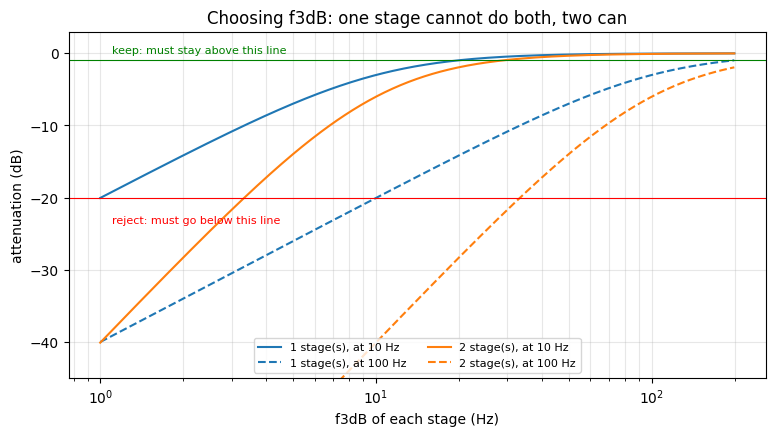

In [9]:
f_keep, f_reject = 10.0, 100.0
max_loss_keep, min_atten_reject = 1.0, 20.0        # dB

print(f"keep {f_keep:g} Hz with at most {max_loss_keep:g} dB loss, reject {f_reject:g} Hz by at least {min_atten_reject:g} dB\n")
print(f"{'stages':>6} {'f3dB per stage must be >=':>27} {'and <=':>10}   verdict")
for n in (1, 2, 3, 4):
    # n identical stages: attenuation = -10*n*log10(1 + (f/fc)^2)
    lo = f_keep / np.sqrt(10 ** (max_loss_keep / (10 * n)) - 1)
    hi = f_reject / np.sqrt(10 ** (min_atten_reject / (10 * n)) - 1)
    verdict = f"OK: pick f3dB in [{lo:.1f}, {hi:.1f}] Hz" if lo <= hi else "IMPOSSIBLE with this many stages"
    print(f"{n:>6} {lo:>24.1f} Hz {hi:>7.1f} Hz   {verdict}")

fc = np.logspace(0, 2.3, 400)                       # per-stage corner, 1 .. 200 Hz
fig, ax = plt.subplots(figsize=(9, 4.5))
for n, color in ((1, 'tab:blue'), (2, 'tab:orange')):
    for f, ls in ((f_keep, '-'), (f_reject, '--')):
        ax.plot(fc, -10 * n * np.log10(1 + (f / fc) ** 2), ls, color=color, label=f'{n} stage(s), at {f:g} Hz')
ax.axhline(-max_loss_keep, color='green', lw=0.8)
ax.axhline(-min_atten_reject, color='red', lw=0.8)
ax.text(1.1, -max_loss_keep + 1, 'keep: must stay above this line', color='green', fontsize=8)
ax.text(1.1, -min_atten_reject - 3.5, 'reject: must go below this line', color='red', fontsize=8)
ax.set_xscale('log')
ax.set_ylim(-45, 3)
ax.set_xlabel('f3dB of each stage (Hz)')
ax.set_ylabel('attenuation (dB)')
ax.set_title('Choosing f3dB: one stage cannot do both, two can')
ax.grid(alpha=0.3, which='both')
ax.legend(fontsize=8, ncol=2, loc='lower center')
plt.show()

How to read this:

- A solid line (10 Hz) must stay **above** the green line, a dashed line (100 Hz) must go **below** the red one. The $f_{3\mathrm{dB}}$ values where both hold at once are the answer.
- **One stage has no answer.** To keep 10 Hz within 1 dB you need $f_{3\mathrm{dB}} \geq 19.7\ \text{Hz}$; to knock 100 Hz down by 20 dB you need $f_{3\mathrm{dB}} \leq 10.1\ \text{Hz}$. The two ranges do not overlap. That is the roll-off of a first-order filter: only 20 dB per decade, so it cannot separate tones a decade apart *and* leave the wanted one alone.
- **Two stages do:** each stage in $[28.6,\ 33.3]$ Hz works. This is the reason lock-in amplifiers offer 6/12/18/24 dB/oct slopes, which are 1 to 4 cascaded stages. Dimension the first, then add stages until the requirement fits.
- The table in the next section is the same exercise for a single stage, over several $f_{3\mathrm{dB}}$ values.

## Two-tone example: separating 10 Hz from 100 Hz

Same idea as before, just shifted up by 10x (still one decade of separation, so the same tradeoff shape repeats, with $\tau$ shrinking by 10x to match):

| f3dB | tau | attenuation @10Hz | attenuation @100Hz |
|---|---|---|---|
| 5 Hz | 31.8 ms | -6.99 dB | -26.0 dB |
| 10 Hz | 15.9 ms | -3.01 dB | -20.0 dB |
| 20 Hz | 8.0 ms | -0.97 dB | -14.2 dB |
| 30 Hz | 5.3 ms | -0.46 dB | -10.8 dB |
| 50 Hz | 3.2 ms | -0.17 dB | -7.0 dB |

Picking $f_{3\mathrm{dB}} = 20\ \text{Hz}$ as a middle-ground: 10 Hz comes through almost untouched (-1 dB) while 100 Hz is knocked down by about -14 dB (~20% of its original amplitude).

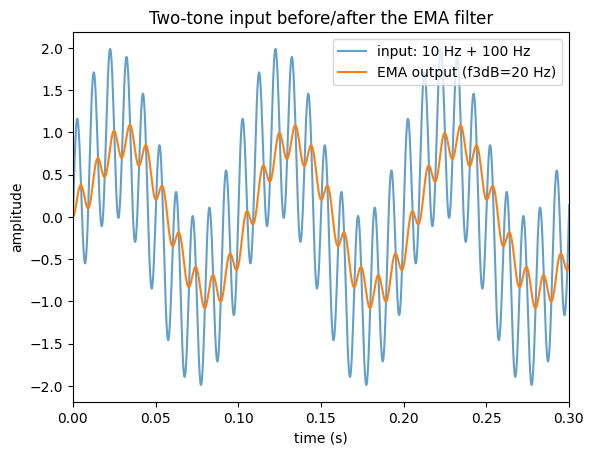

In [10]:
Fs = 5000.0          # demo sample rate, independent of the real ADC rate (still unanswered)
duration = 1.0       # 1 Hz FFT resolution so the 10/100 Hz tones land on exact bins
t_demo = np.arange(0, duration, 1 / Fs)
x_tone = np.sin(2 * np.pi * 10 * t_demo) + np.sin(2 * np.pi * 100 * t_demo)

f3db_choice = 20.0   # the middle-ground pick from the table above
tau_choice = 1 / (2 * np.pi * f3db_choice)
alpha_choice = alpha_from_tau(tau_choice, 1 / Fs)
y_tone = ema_filter(x_tone, alpha_choice)

plt.plot(t_demo, x_tone, label='input: 10 Hz + 100 Hz', alpha=0.7)
plt.plot(t_demo, y_tone, label=f'EMA output (f3dB={f3db_choice:.0f} Hz)')
plt.xlim(0, 0.3)
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.legend()
plt.title('Two-tone input before/after the EMA filter')
plt.show()

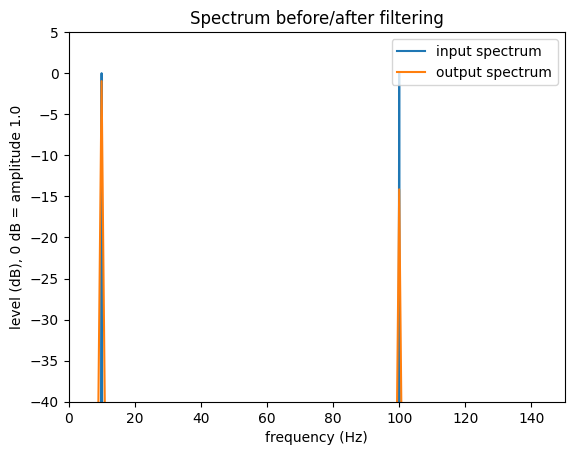

 10 Hz: measured attenuation =  -0.97 dB, theory =  -0.97 dB
100 Hz: measured attenuation = -14.14 dB, theory = -14.15 dB


In [11]:
scale = len(x_tone) / 2           # a unit-amplitude sine gives |FFT| = N/2, so dividing makes it read 1.0 = 0 dB
X = np.fft.rfft(x_tone) / scale
Y = np.fft.rfft(y_tone) / scale
freqs = np.fft.rfftfreq(len(x_tone), d=1 / Fs)

plt.plot(freqs, 20 * np.log10(np.abs(X) + 1e-12), label='input spectrum')
plt.plot(freqs, 20 * np.log10(np.abs(Y) + 1e-12), label='output spectrum')
plt.xlim(0, 150)
plt.ylim(-40, 5)  # zoom in: the other bins are ~floating-point zero (-200+ dB),
                  # which would otherwise squash the real peaks into the top sliver
plt.xlabel('frequency (Hz)')
plt.ylabel('level (dB), 0 dB = amplitude 1.0')
plt.legend()
plt.title('Spectrum before/after filtering')
plt.show()

for f in [10, 100]:
    k = int(round(f * duration))
    measured_db = 20 * np.log10(np.abs(Y[k]) / np.abs(X[k]))
    theory_db = -10 * np.log10(1 + (f / f3db_choice) ** 2)
    print(f'{f:>3} Hz: measured attenuation = {measured_db:6.2f} dB, theory = {theory_db:6.2f} dB')

### Reading the numbers: what do these dB mean?

Each input tone has amplitude 1.0, so it sits at **0 dB** on the plot. After the filter:

| tone | level after | amplitude ratio | meaning |
|---|---|---|---|
| 10 Hz | -0.97 dB | 0.894 | the wanted tone loses about 11% of its amplitude |
| 100 Hz | -14.1 dB | 0.196 | the unwanted tone is cut to about 20% of its amplitude |

- **The amplitude ratio is $10^{\text{dB}/20}$.** -14 dB is $10^{-14/20} = 0.2$. Anchors: -6 dB is half, -20 dB is a tenth, -40 dB is a hundredth.
- **Only the difference is meaningful here.** In an earlier version of this plot the peaks sat at about 68 dB and dropped to about 54 dB. The 68 came from the FFT's own scale (a unit sine gives $|\mathrm{FFT}| = N/2 = 2500$, and $20 \log_{10}(2500) = 68$), not from the signal. The drop of 14 dB is the real information; the plot now divides by $N/2$ so that a unit tone reads 0 dB, as in the dsp02 spectrum plots.
- **dB add up when you cascade.** Two identical stages give twice the dB: -14 dB becomes -28 dB (amplitude 0.04).
- **What it means for a measurement.** Attenuation is only useful compared with how big the interference is. If the 100 Hz interference is 10 times larger than your signal (+20 dB) and you cut it by 14 dB, it is still 2 times larger than your signal (+6 dB). To get it down to 10% of the signal you need $20\ \text{dB} + 20\ \text{dB} = 40\ \text{dB}$ of attenuation. So decide the required attenuation from the **ratio** of interference to signal, then use the procedure in "How do we choose $\tau$?" to find the stages and $f_{3\mathrm{dB}}$.
- The measured values match the closed-form theory $-10 \log_{10}\!\left(1 + (f/f_{3\mathrm{dB}})^2\right)$ to 0.01 dB, so the formula holds for a real two-tone signal, not only for one swept sinusoid.